# Assignment 7
## UCS420 - Cognitive Computing
### Topic: NumPy, Pandas, Matplotlib — E-commerce Sales Analysis

**Name:** Jatin Kumar

**Roll Number:** 1024170438

**Course:** UCS420 - Cognitive Computing

**Assignment:** 7 - NumPy, Pandas, Matplotlib Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print('Libraries imported successfully!')

Libraries imported successfully!


---
## Q1. E-commerce Sales Data Analysis
You are a data analyst at an e-commerce company. Analyze sales data using NumPy, Pandas, and Matplotlib.
**Roll number is used as the random seed for reproducibility.**

### Part I: Randomized Sales Data Generation (NumPy)

In [2]:
# Step 1: Initialize random seed using roll number
ROLL_NUMBER = 1024170438  # Roll number as seed
np.random.seed(ROLL_NUMBER)
print(f'Random seed initialized: {ROLL_NUMBER}')

# Step 2: Generate sales data for 12 months, 4 product categories
# Categories: Electronics, Clothing, Home & Kitchen, Sports
# Sales values between 1000 and 5000
lower = 1000
upper = 5000
sales_array = np.random.randint(lower, upper + 1, size=(12, 4))

print(f'\nSales array shape: {sales_array.shape}')
print('\nRaw sales data (12 months x 4 categories):')
print(sales_array)


Random seed initialized: 1024170438

Sales array shape: (12, 4)

Raw sales data (12 months x 4 categories):
[[2072 4816 1096 2291]
 [2946 3015 2016 2324]
 [1628 3321 4977 4842]
 [1544 2853 2123 3392]
 [4567 4812 1597 4460]
 [3217 1955 2453 1993]
 [4766 4308 3205 3675]
 [4456 1990 1866 2046]
 [2680 4725 4675 4615]
 [3736 2048 2029 2862]
 [2999 4615 1525 2512]
 [3790 2354 3330 2348]]


In [3]:
# Step 3: Convert to Pandas DataFrame
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

df = pd.DataFrame(
    sales_array,
    columns=['Electronics', 'Clothing', 'Home & Kitchen', 'Sports'],
    index=months
)

print('Sales DataFrame:')
print(df)

Sales DataFrame:
     Electronics  Clothing  Home & Kitchen  Sports
Jan         2072      4816            1096    2291
Feb         2946      3015            2016    2324
Mar         1628      3321            4977    4842
Apr         1544      2853            2123    3392
May         4567      4812            1597    4460
Jun         3217      1955            2453    1993
Jul         4766      4308            3205    3675
Aug         4456      1990            1866    2046
Sep         2680      4725            4675    4615
Oct         3736      2048            2029    2862
Nov         2999      4615            1525    2512
Dec         3790      2354            3330    2348


### Part II: Data Manipulation and Analysis (Pandas)

In [4]:
# Step 1: Display first 5 rows and summary statistics
print('First 5 rows:')
print(df.head())

print('\nSummary Statistics:')
print(df.describe())

First 5 rows:
     Electronics  Clothing  Home & Kitchen  Sports
Jan         2072      4816            1096    2291
Feb         2946      3015            2016    2324
Mar         1628      3321            4977    4842
Apr         1544      2853            2123    3392
May         4567      4812            1597    4460

Summary Statistics:
       Electronics     Clothing  Home & Kitchen       Sports
count    12.000000    12.000000       12.000000    12.000000
mean   3200.083333  3401.000000     2574.333333  3113.333333
std    1103.526863  1187.316378     1233.082415  1051.149097
min    1544.000000  1955.000000     1096.000000  1993.000000
25%    2528.000000  2277.500000     1798.750000  2315.750000
50%    3108.000000  3168.000000     2076.000000  2687.000000
75%    3956.500000  4642.500000     3236.250000  3871.250000
max    4766.000000  4816.000000     4977.000000  4842.000000


In [5]:
# Step 2: Total sales per category and per month
print('Total Sales per Category (across all months):')
print(df.sum())

print('\nTotal Sales per Month (across all categories):')
print(df.sum(axis=1))

Total Sales per Category (across all months):
Electronics       38401
Clothing          40812
Home & Kitchen    30892
Sports            37360
dtype: int64

Total Sales per Month (across all categories):
Jan    10275
Feb    10301
Mar    14768
Apr     9912
May    15436
Jun     9618
Jul    15954
Aug    10358
Sep    16695
Oct    10675
Nov    11651
Dec    11822
dtype: int64


In [6]:
# Step 3: Average sales growth between consecutive months for each category
monthly_diff = df.diff().dropna()  # Month-to-month difference
avg_growth = monthly_diff.mean()

print('Average Sales Growth per Category (month-over-month):')
print(avg_growth.round(2))

Average Sales Growth per Category (month-over-month):
Electronics       156.18
Clothing         -223.82
Home & Kitchen    203.09
Sports              5.18
dtype: float64


In [7]:
# Step 4: Add Total Sales and Growth Rate columns
df['Total Sales'] = df[['Electronics', 'Clothing', 'Home & Kitchen', 'Sports']].sum(axis=1)
df['Growth Rate'] = df['Total Sales'].pct_change() * 100  # Percentage change from previous month

print('DataFrame with Total Sales and Growth Rate:')
print(df.round(2))

DataFrame with Total Sales and Growth Rate:
     Electronics  Clothing  Home & Kitchen  Sports  Total Sales  Growth Rate
Jan         2072      4816            1096    2291        10275          NaN
Feb         2946      3015            2016    2324        10301         0.25
Mar         1628      3321            4977    4842        14768        43.36
Apr         1544      2853            2123    3392         9912       -32.88
May         4567      4812            1597    4460        15436        55.73
Jun         3217      1955            2453    1993         9618       -37.69
Jul         4766      4308            3205    3675        15954        65.88
Aug         4456      1990            1866    2046        10358       -35.08
Sep         2680      4725            4675    4615        16695        61.18
Oct         3736      2048            2029    2862        10675       -36.06
Nov         2999      4615            1525    2512        11651         9.14
Dec         3790      2354      

In [8]:
# Step 5: Apply randomized discount based on roll number parity
# ROLL_NUMBER = 1024170438 -> even -> 10% discount on Electronics

if ROLL_NUMBER % 2 == 0:
    discount_category = 'Electronics'
    discount_rate = 0.10
    print(f'Roll number is EVEN -> Applying {int(discount_rate*100)}% discount to {discount_category}')
else:
    discount_category = 'Clothing'
    discount_rate = 0.15
    print(f'Roll number is ODD -> Applying {int(discount_rate*100)}% discount to {discount_category}')

df_discounted = df.copy()
df_discounted[discount_category] = df_discounted[discount_category] * (1 - discount_rate)

print(f'\n{discount_category} sales after {int(discount_rate*100)}% discount:')
print(df_discounted[[discount_category]].round(2))


Roll number is EVEN -> Applying 10% discount to Electronics

Electronics sales after 10% discount:
     Electronics
Jan       1864.8
Feb       2651.4
Mar       1465.2
Apr       1389.6
May       4110.3
Jun       2895.3
Jul       4289.4
Aug       4010.4
Sep       2412.0
Oct       3362.4
Nov       2699.1
Dec       3411.0


### Part III: Visualizations (Matplotlib and Seaborn)

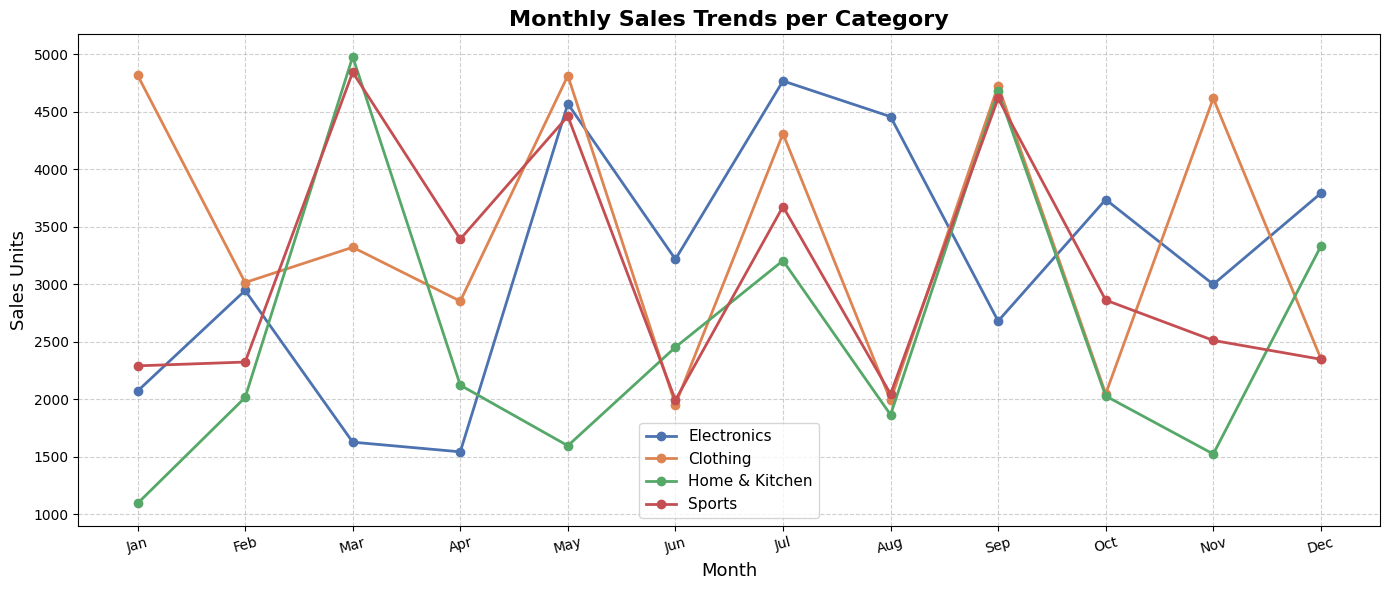

In [9]:
# Visualization 1: Line plots for monthly sales trends per category
product_cats = ['Electronics', 'Clothing', 'Home & Kitchen', 'Sports']

fig, ax = plt.subplots(figsize=(14, 6))

colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
for cat, color in zip(product_cats, colors):
    ax.plot(months, df[cat], marker='o', linewidth=2, color=color, label=cat)

ax.set_title('Monthly Sales Trends per Category', fontsize=16, fontweight='bold')
ax.set_xlabel('Month', fontsize=13)
ax.set_ylabel('Sales Units', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, linestyle='--', alpha=0.6)
ax.tick_params(axis='x', labelrotation=15)

plt.tight_layout()
plt.show()

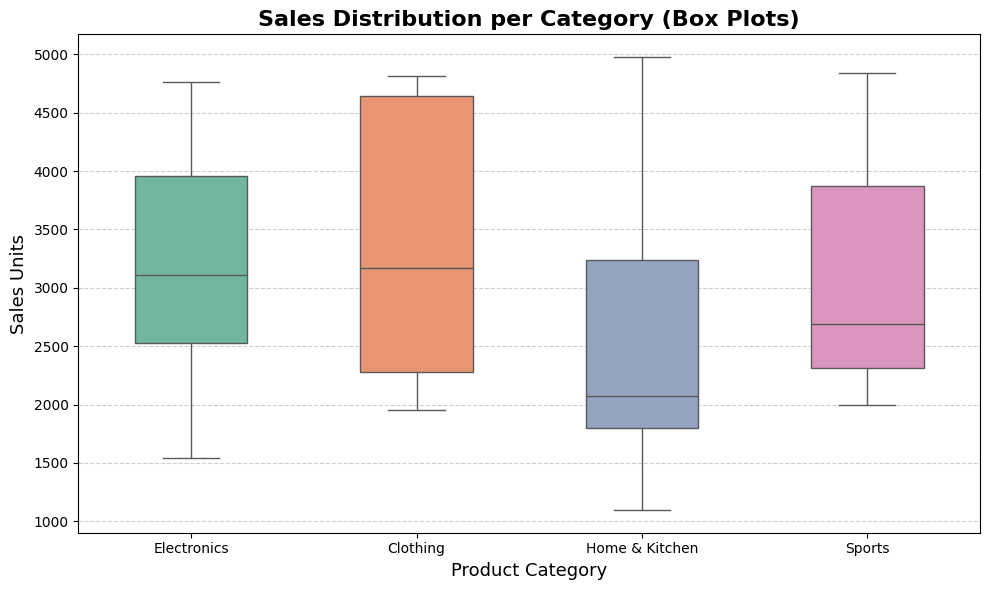

In [10]:
# Visualization 2: Box plots for sales distribution per category
df_box = df[['Electronics', 'Clothing', 'Home & Kitchen', 'Sports']]

fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(data=df_box, palette='Set2', ax=ax, width=0.5,
            flierprops=dict(marker='o', color='red', markersize=8))

ax.set_title('Sales Distribution per Category (Box Plots)', fontsize=16, fontweight='bold')
ax.set_xlabel('Product Category', fontsize=13)
ax.set_ylabel('Sales Units', fontsize=13)
ax.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

---
## Q2. NumPy Array Operations
For the array: `array = np.array([[1, -2, 3], [-4, 5, -6]])`
- i. Element-wise absolute value
- ii. 25th, 50th, 75th percentiles (flattened, per column, per row)
- iii. Mean, Median, and Standard Deviation (flattened, per column, per row)

In [11]:
array = np.array([[1, -2, 3], [-4, 5, -6]])
print('Original array:')
print(array)

# i. Element-wise absolute value
print('\ni. Element-wise absolute value:')
print(np.abs(array))

Original array:
[[ 1 -2  3]
 [-4  5 -6]]

i. Element-wise absolute value:
[[1 2 3]
 [4 5 6]]


In [12]:
# ii. Percentiles
percentiles = [25, 50, 75]

print('ii. Percentiles:\n')
print('  Flattened array percentiles:')
for p in percentiles:
    print(f'    {p}th percentile: {np.percentile(array, p)}')

print('\n  Per-column percentiles (axis=0):')
for p in percentiles:
    print(f'    {p}th percentile: {np.percentile(array, p, axis=0)}')

print('\n  Per-row percentiles (axis=1):')
for p in percentiles:
    print(f'    {p}th percentile: {np.percentile(array, p, axis=1)}')

ii. Percentiles:

  Flattened array percentiles:
    25th percentile: -3.5
    50th percentile: -0.5
    75th percentile: 2.5

  Per-column percentiles (axis=0):
    25th percentile: [-2.75 -0.25 -3.75]
    50th percentile: [-1.5  1.5 -1.5]
    75th percentile: [-0.25  3.25  0.75]

  Per-row percentiles (axis=1):
    25th percentile: [-0.5 -5. ]
    50th percentile: [ 1. -4.]
    75th percentile: [2.  0.5]


In [13]:
# iii. Mean, Median, Standard Deviation
print('iii. Mean, Median, Standard Deviation:\n')

print('  Flattened:')
print(f'    Mean:  {np.mean(array)}')
print(f'    Median:{np.median(array)}')
print(f'    Std:   {np.std(array):.4f}')

print('\n  Per column (axis=0):')
print(f'    Mean:  {np.mean(array, axis=0)}')
print(f'    Median:{np.median(array, axis=0)}')
print(f'    Std:   {np.std(array, axis=0)}')

print('\n  Per row (axis=1):')
print(f'    Mean:  {np.mean(array, axis=1)}')
print(f'    Median:{np.median(array, axis=1)}')
print(f'    Std:   {np.std(array, axis=1)}')

iii. Mean, Median, Standard Deviation:

  Flattened:
    Mean:  -0.5
    Median:-0.5
    Std:   3.8622

  Per column (axis=0):
    Mean:  [-1.5  1.5 -1.5]
    Median:[-1.5  1.5 -1.5]
    Std:   [2.5 3.5 4.5]

  Per row (axis=1):
    Mean:  [ 0.66666667 -1.66666667]
    Median:[ 1. -4.]
    Std:   [2.05480467 4.78423336]


---
## Q3. Floor, Ceiling, Truncation, and Rounding
For the array: `a = np.array([-1.8, -1.6, -0.5, 0.5, 1.6, 1.8, 3.0])`
- Find floor, ceiling, truncated, and rounded values.

In [14]:
a = np.array([-1.8, -1.6, -0.5, 0.5, 1.6, 1.8, 3.0])
print('Original array:  ', a)
print()
print('Floor values:    ', np.floor(a))
print('Ceiling values:  ', np.ceil(a))
print('Truncated values:', np.trunc(a))
print('Rounded values:  ', np.round(a))

Original array:   [-1.8 -1.6 -0.5  0.5  1.6  1.8  3. ]

Floor values:     [-2. -2. -1.  0.  1.  1.  3.]
Ceiling values:   [-1. -1. -0.  1.  2.  2.  3.]
Truncated values: [-1. -1. -0.  0.  1.  1.  3.]
Rounded values:   [-2. -2. -0.  0.  2.  2.  3.]


---
## Q4. Swap Two Elements in a List Using a Temporary Variable
Write a Python program to swap two elements in a list using a temporary variable.

In [15]:
def swap_list_elements(lst, i, j):
    '''Swaps elements at index i and j in a list using a temporary variable.'''
    temp = lst[i]   # Store element at index i in temp
    lst[i] = lst[j] # Assign element at index j to index i
    lst[j] = temp   # Assign temp (original i) to index j
    return lst

# Example
my_list = [10, 20, 30, 40, 50]
print('Original list:   ', my_list)

# Swap elements at index 1 and 3
swapped_list = swap_list_elements(my_list, 1, 3)
print('After swap (i=1, j=3):', swapped_list)

Original list:    [10, 20, 30, 40, 50]
After swap (i=1, j=3): [10, 40, 30, 20, 50]


---
## Q5. Swap Two Elements in a Set by Converting to a List
Write a Python program to swap two elements in a set by converting it to a list first.

In [16]:
def swap_set_elements(s, elem1, elem2):
    '''
    Swaps two elements in a set by converting to a list,
    swapping, and converting back to a set.
    Note: Sets are unordered; this swaps the VALUES at the positions
    found after list conversion.
    '''
    # Convert set to list (for indexing support)
    lst = list(s)
    print(f'Set converted to list: {lst}')

    # Find indices of the two elements
    if elem1 not in lst or elem2 not in lst:
        print('One or both elements not found in the set!')
        return s

    idx1 = lst.index(elem1)
    idx2 = lst.index(elem2)

    # Swap using temporary variable
    temp = lst[idx1]
    lst[idx1] = lst[idx2]
    lst[idx2] = temp

    print(f'List after swap ({elem1} <-> {elem2}): {lst}')

    # Convert back to set
    return set(lst)


# Example
my_set = {10, 20, 30, 40, 50}
print('Original set:', my_set)

# Swap elements 20 and 40
result_set = swap_set_elements(my_set, 20, 40)
print('Resulting set:', result_set)

Original set: {50, 20, 40, 10, 30}
Set converted to list: [50, 20, 40, 10, 30]
List after swap (20 <-> 40): [50, 40, 20, 10, 30]
Resulting set: {40, 10, 50, 20, 30}
